# Stakeholder Salience Bubble Chart
### Mitchell, Agle & Wood (1997) — Power / Legitimacy / Urgency

District curriculum authoring workflow — GPT Image 2 migration case.

**Plot mapping**

| Element | Variable | Rationale |
|---|---|---|
| X axis | Power | Structural, slow-moving |
| Y axis | Legitimacy | Structural, slow-moving |
| Bubble **area** | Urgency | Volatile — the attribute that shifts fastest |
| Colour | Salience class | Derived from the scores |

Bubble area is proportional to urgency (radius scales as √U), so a 5 reads as
five times a 1 rather than twenty-five times.

**Data source:** external CSV — see section 1.
**Excluded from this version:** `q` Bargaining unit, `s` Procurement.
**Bubble size:** `SIZE_SCALE = 1.20` (20% larger than the baseline).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Configuration — where the data lives

Scores are read from a CSV rather than hard-coded, so the analysis can be
revised without touching the notebook.

Set `DATA_DIR` to the folder holding the file. The Windows path below uses a
**raw string** (`r"..."`) so backslashes are taken literally. This matters:
without the `r`, `\U` in `\Users` is read as the start of a Unicode escape and
Python raises a `SyntaxError` before the notebook even runs.

If `DATA_DIR` is unreachable — running on macOS, a colleague's machine, or a
hosted kernel — the notebook falls back to the working directory and says so
rather than failing.

In [2]:
DATA_DIR = Path(r"C:\Users\corre\OneDrive\Documents\Flavio - Copy (2)\Harvard\CSCI - E-184\Final Project")
CSV_NAME = "stakeholder_salience.csv"

if not DATA_DIR.exists():
    print("DATA_DIR not found:\n  " + str(DATA_DIR))
    print("Falling back to the working directory.")
    DATA_DIR = Path.cwd()

CSV_PATH = DATA_DIR / CSV_NAME
OUT_DIR = DATA_DIR

print("Reading from : " + str(CSV_PATH))
print("Writing to   : " + str(OUT_DIR))

DATA_DIR not found:
  C:\Users\corre\OneDrive\Documents\Flavio - Copy (2)\Harvard\CSCI - E-184\Final Project
Falling back to the working directory.
Reading from : /home/claude/stakeholder_salience.csv
Writing to   : /home/claude


## 2. Create the template (first run only)

Run this once to write a starter CSV containing all nineteen stakeholders,
then edit it in Excel and re-run from section 3 onwards.

`WRITE_TEMPLATE` is `False` by default so a later re-run cannot quietly
overwrite your edits, and the cell refuses to write if the file already
exists.

In [3]:
WRITE_TEMPLATE = False

TEMPLATE = [
    ("a", "Students K-8",           1, 5, 4, False),
    ("b", "Parents / guardians",    2, 5, 3, False),
    ("c", "Authoring staff",        2, 4, 5, False),
    ("d", "Technical staff",        4, 4, 4, False),
    ("e", "General Counsel",        4, 5, 4, False),
    ("f", "Teachers",               2, 4, 3, False),
    ("g", "Principals",             3, 4, 2, False),
    ("h", "Board of Education",     5, 5, 2, False),
    ("i", "OpenAI",                 5, 3, 1, False),
    ("j", "Competing vendors",      1, 2, 3, False),
    ("k", "Political officials",    4, 4, 2, False),
    ("l", "Training-set artists",   1, 4, 3, False),
    ("m", "Local illustrators",     1, 4, 4, False),
    ("n", "IEP / VI students",      4, 5, 4, True),
    ("o", "Superintendent",         5, 5, 5, False),
    ("p", "Regulators",             5, 5, 1, False),
    ("q", "Bargaining unit",        3, 4, 3, False),
    ("r", "504 coordinator",        4, 4, 4, True),
    ("s", "Procurement",            3, 4, 4, False),
]

if not WRITE_TEMPLATE:
    print("WRITE_TEMPLATE is False - set it to True to create the starter file.")
elif CSV_PATH.exists():
    print("Refusing to overwrite existing file:\n  " + str(CSV_PATH))
else:
    pd.DataFrame(
        TEMPLATE,
        columns=["ref", "stakeholder", "power",
                 "legitimacy", "urgency", "power_derived"],
    ).to_csv(CSV_PATH, index=False)
    print("Template written to " + str(CSV_PATH))

WRITE_TEMPLATE is False - set it to True to create the starter file.


## 3. Load and validate

**Required columns:** `ref`, `stakeholder`, `power`, `legitimacy`, `urgency`.

**Optional columns**

- `power_derived` — `True` where power comes from a statutory instrument
  (Section 504 / IDEA / ADA) rather than being held directly by the
  stakeholder. Defaults to `False`.
- `salience_class` — if absent or blank it is **derived from the scores**.
  Deriving is the safer default: the class then cannot drift out of step with
  the numbers when someone edits a score in Excel. If you do supply it and it
  disagrees with the scores, the cell prints a warning rather than silently
  picking one.

Validation fails loudly rather than plotting something wrong — missing
columns, non-numeric scores, values outside 1–5, and duplicate refs all
raise.

In [4]:
THRESHOLD = 3.0   # an attribute counts as present at >= 3

REQUIRED = ["ref", "stakeholder", "power", "legitimacy", "urgency"]
SCORES = ["power", "legitimacy", "urgency"]

# Mitchell, Agle & Wood (1997) seven-class typology
TYPOLOGY = {
    (True,  True,  True):  "Definitive",
    (True,  True,  False): "Dominant",
    (True,  False, True):  "Dangerous",
    (False, True,  True):  "Dependent",
    (True,  False, False): "Dormant",
    (False, True,  False): "Discretionary",
    (False, False, True):  "Demanding",
    (False, False, False): "Non-stakeholder",
}


def classify(power, legitimacy, urgency, threshold=THRESHOLD):
    key = (power >= threshold, legitimacy >= threshold, urgency >= threshold)
    return TYPOLOGY[key]


def load_scores(path):
    if not path.exists():
        raise FileNotFoundError(
            "No CSV at " + str(path) + "\n"
            "Check DATA_DIR in section 1, or set WRITE_TEMPLATE = True in section 2."
        )

    frame = pd.read_csv(path)
    frame.columns = [str(col).strip().lower() for col in frame.columns]

    missing = [col for col in REQUIRED if col not in frame.columns]
    if missing:
        raise ValueError(
            "Missing required column(s): " + str(missing) + "\n"
            "Found: " + str(list(frame.columns))
        )

    for col in SCORES:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")

    bad = frame[frame[SCORES].isna().any(axis=1)]
    if not bad.empty:
        raise ValueError(
            "Non-numeric or blank score(s):\n"
            + bad[["ref", "stakeholder"] + SCORES].to_string(index=False)
        )

    out_of_range = frame[
        (frame[SCORES] < 1).any(axis=1) | (frame[SCORES] > 5).any(axis=1)
    ]
    if not out_of_range.empty:
        raise ValueError(
            "Scores must be between 1 and 5:\n"
            + out_of_range[["ref", "stakeholder"] + SCORES].to_string(index=False)
        )

    frame["ref"] = frame["ref"].astype(str).str.strip()
    dupes = frame.loc[frame["ref"].duplicated(keep=False), "ref"].unique()
    if len(dupes):
        raise ValueError("Duplicate ref value(s): " + str(list(dupes)))

    if "power_derived" not in frame.columns:
        frame["power_derived"] = False
    frame["power_derived"] = (
        frame["power_derived"].astype(str).str.strip().str.lower()
        .isin(["true", "1", "yes", "y"])
    )

    derived = frame.apply(
        lambda r: classify(r["power"], r["legitimacy"], r["urgency"]), axis=1
    )

    if "salience_class" not in frame.columns:
        frame["salience_class"] = derived
        print("salience_class not supplied - derived from the scores.")
    else:
        blank = frame["salience_class"].isna() | (
            frame["salience_class"].astype(str).str.strip() == ""
        )
        frame.loc[blank, "salience_class"] = derived[blank]
        supplied = frame["salience_class"].astype(str).str.strip()
        mismatch = frame[(~blank) & (supplied != derived)]
        if not mismatch.empty:
            print("WARNING - supplied salience_class disagrees with the scores:")
            print(
                mismatch[["ref", "stakeholder", "salience_class"]]
                .assign(derived_from_scores=derived[mismatch.index])
                .to_string(index=False)
            )

    return frame


scores = load_scores(CSV_PATH)
print("Loaded " + str(len(scores)) + " stakeholders from " + CSV_PATH.name)
scores

salience_class not supplied - derived from the scores.
Loaded 19 stakeholders from stakeholder_salience.csv


,ref,stakeholder,power,legitimacy,urgency,power_derived,salience_class
0,a,Students K-8,1,5,4,False,Dependent
1,b,Parents / guardians,2,5,3,False,Dependent
2,c,Authoring staff,2,4,5,False,Dependent
3,d,Technical staff,4,4,4,False,Definitive
4,e,General Counsel,4,5,4,False,Definitive
5,f,Teachers,2,4,3,False,Dependent
6,g,Principals,3,4,2,False,Dominant
7,h,Board of Education,5,5,2,False,Dominant
8,i,OpenAI,5,3,1,False,Dominant
9,j,Competing vendors,1,2,3,False,Demanding


## 4. Exclusions and composite indices

Set `EXCLUDE` to the `ref` letters to leave out — currently `q` Bargaining
unit and `s` Procurement. Use an empty set to plot every row.

Two composite indices are computed:

- **Σ (sum)** treats the attributes as *compensatory* — strength in one
  offsets a deficit in another.
- **GM (geometric mean)** treats them as *conjunctive* — a low score on any
  attribute suppresses the composite. This is the more faithful reading of
  Mitchell, because a missing attribute produces a categorically different
  class, not a slightly weaker one.

In [5]:
EXCLUDE = {"q", "s"}

unknown = EXCLUDE - set(scores["ref"])
if unknown:
    print("WARNING - EXCLUDE contains ref(s) not in the data: " + str(sorted(unknown)))

df = scores[~scores["ref"].isin(EXCLUDE)].reset_index(drop=True)

df["sum"] = df[SCORES].sum(axis=1)
df["geom_mean"] = (
    df["power"] * df["legitimacy"] * df["urgency"]
).pow(1 / 3).round(2)

print(str(len(df)) + " plotted, " + str(len(scores) - len(df)) + " excluded")
df.sort_values("geom_mean", ascending=False)

17 plotted, 2 excluded


,ref,stakeholder,power,legitimacy,urgency,power_derived,salience_class,sum,geom_mean
14,o,Superintendent,5,5,5,False,Definitive,15,5.00
13,n,IEP / VI students,4,5,4,True,Definitive,13,4.31
4,e,General Counsel,4,5,4,False,Definitive,13,4.31
16,r,504 coordinator,4,4,4,True,Definitive,12,4.00
3,d,Technical staff,4,4,4,False,Definitive,12,4.00
7,h,Board of Education,5,5,2,False,Dominant,12,3.68
2,c,Authoring staff,2,4,5,False,Dependent,11,3.42
10,k,Political officials,4,4,2,False,Dominant,10,3.17
1,b,Parents / guardians,2,5,3,False,Dependent,10,3.11
15,p,Regulators,5,5,1,False,Dominant,11,2.92


## 5. Layout parameters

`SIZE_SCALE` is the only knob you normally need. `BASE_AREA` sets the area of
a bubble at urgency = 1, in matplotlib points²; everything scales linearly
from there, so area stays proportional to urgency.

The palette covers all seven Mitchell classes, so a rescored CSV that produces
a Dangerous or Discretionary stakeholder still plots correctly.

In [6]:
SIZE_SCALE = 1.20          # 20% larger than baseline
BASE_AREA  = 300           # points^2 at urgency = 1

PALETTE = {
    "Definitive":      "#2a78d6",
    "Dominant":        "#4a3aa7",
    "Dependent":       "#eb6834",
    "Dangerous":       "#e34948",
    "Dormant":         "#eda100",
    "Discretionary":   "#1baf7a",
    "Demanding":       "#898781",
    "Non-stakeholder": "#c3c2b7",
}

CLASS_ORDER = ["Definitive", "Dominant", "Dependent", "Dangerous",
               "Dormant", "Discretionary", "Demanding", "Non-stakeholder"]

unmapped = set(df["salience_class"]) - set(PALETTE)
if unmapped:
    raise ValueError("No colour defined for class(es): " + str(sorted(unmapped)))

df["area"] = df["urgency"] * BASE_AREA * SIZE_SCALE
df[["ref", "stakeholder", "urgency", "salience_class", "area"]]

,ref,stakeholder,urgency,salience_class,area
0,a,Students K-8,4,Dependent,1440.0
1,b,Parents / guardians,3,Dependent,1080.0
2,c,Authoring staff,5,Dependent,1800.0
3,d,Technical staff,4,Definitive,1440.0
4,e,General Counsel,4,Definitive,1440.0
5,f,Teachers,3,Dependent,1080.0
6,g,Principals,2,Dominant,720.0
7,h,Board of Education,2,Dominant,720.0
8,i,OpenAI,1,Dominant,360.0
9,j,Competing vendors,3,Demanding,1080.0


## 6. Collision offsets

Several stakeholders share identical (power, legitimacy) coordinates. Rather
than hard-coding nudges, co-located groups are detected and fanned evenly
around a small circle — deterministic, so the figure is reproducible and stays
correct if you edit any score in the CSV.

In [7]:
def spread(frame, radius=0.17):
    """Fan co-located points around a small circle. Returns (dx, dy) arrays."""
    dx = np.zeros(len(frame))
    dy = np.zeros(len(frame))
    for _, idx in frame.groupby(["power", "legitimacy"]).groups.items():
        pos = [frame.index.get_loc(i) for i in idx]
        n = len(pos)
        if n == 1:
            continue
        for k, p in enumerate(pos):
            theta = 2 * np.pi * k / n + np.pi / 2
            dx[p] = radius * np.cos(theta)
            dy[p] = radius * np.sin(theta)
    return dx, dy


df["dx"], df["dy"] = spread(df)
df["x"] = df["power"] + df["dx"]
df["y"] = df["legitimacy"] + df["dy"]

moved = df.loc[df["dx"].abs() + df["dy"].abs() > 0,
               ["ref", "stakeholder", "power", "legitimacy"]]
print(str(len(moved)) + " stakeholder(s) offset to avoid overlap")
moved

12 stakeholder(s) offset to avoid overlap


,ref,stakeholder,power,legitimacy
2,c,Authoring staff,2,4
3,d,Technical staff,4,4
4,e,General Counsel,4,5
5,f,Teachers,2,4
7,h,Board of Education,5,5
10,k,Political officials,4,4
11,l,Training-set artists,1,4
12,m,Local illustrators,1,4
13,n,IEP / VI students,4,5
14,o,Superintendent,5,5


## 7. The chart

Quadrant guides sit at the 3.0 threshold on both axes. With urgency on bubble
area, the four quadrants plus bubble size reproduce all seven Mitchell classes:

| Region | Small bubble (U < 3) | Large bubble (U ≥ 3) |
|---|---|---|
| Upper right | Dominant | Definitive |
| Upper left | Discretionary | **Dependent** |
| Lower right | Dormant | Dangerous |
| Lower left | *non-stakeholder* | Demanding |

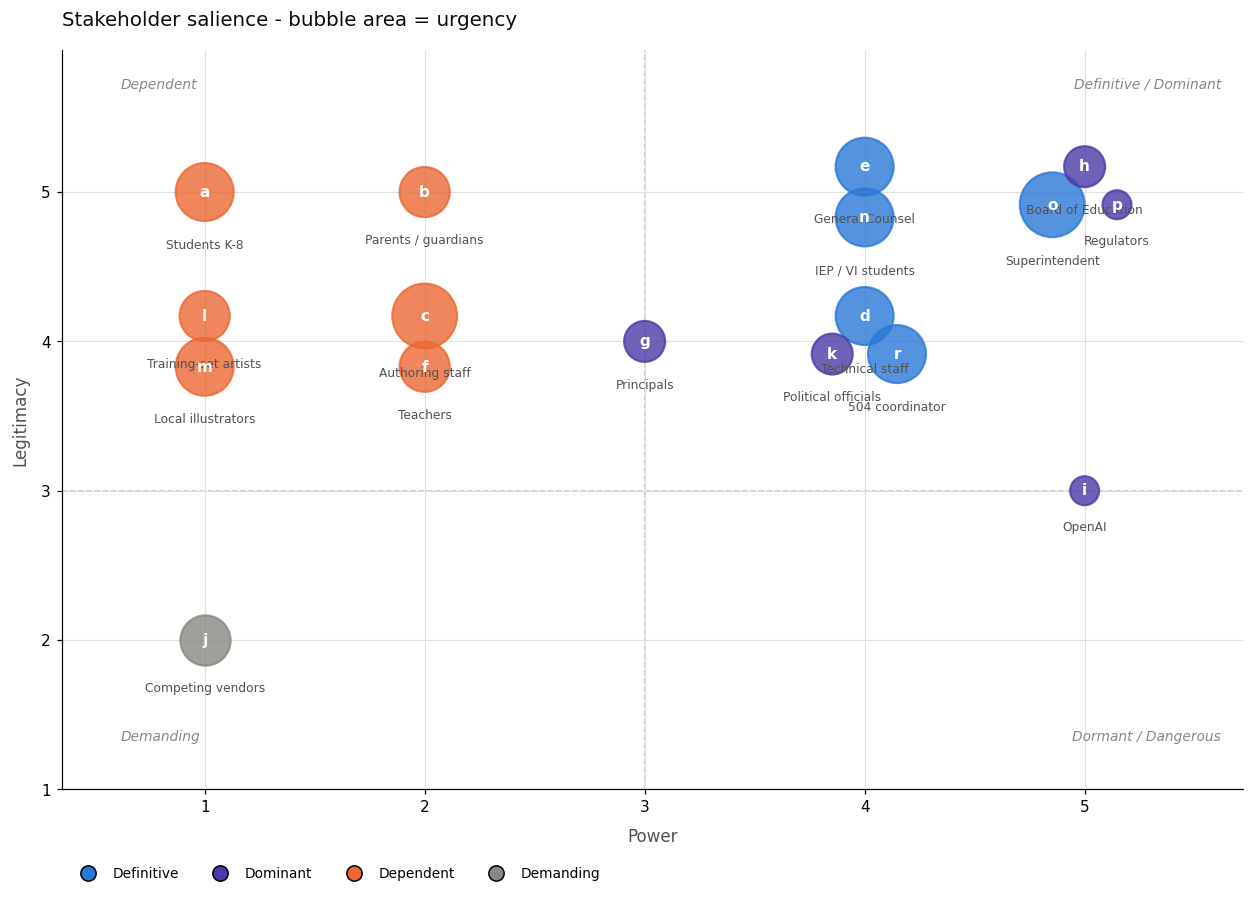

In [8]:
fig, ax = plt.subplots(figsize=(11.5, 8.2))

ax.axvline(THRESHOLD, color="#c3c2b7", lw=1, ls="--", zorder=0)
ax.axhline(THRESHOLD, color="#c3c2b7", lw=1, ls="--", zorder=0)
ax.grid(True, color="#e1e0d9", lw=0.7, zorder=0)
ax.set_axisbelow(True)

for cls in CLASS_ORDER:
    sub = df[df["salience_class"] == cls]
    if sub.empty:
        continue
    ax.scatter(
        sub["x"], sub["y"], s=sub["area"],
        color=PALETTE[cls], alpha=0.80,
        edgecolors=PALETTE[cls], linewidths=1.4, zorder=3,
    )

for _, r in df.iterrows():
    ax.annotate(r["ref"], (r["x"], r["y"]), ha="center", va="center",
                color="white", fontsize=10, fontweight="bold", zorder=4)
    ax.annotate(
        r["stakeholder"],
        (r["x"], r["y"]),
        xytext=(0, -(np.sqrt(r["area"] / np.pi) + 9)),
        textcoords="offset points",
        ha="center", va="top", fontsize=8, color="#52514e", zorder=4,
    )

for x, y, label in [
    (0.62, 5.72, "Dependent"),
    (5.62, 5.72, "Definitive / Dominant"),
    (0.62, 1.35, "Demanding"),
    (5.62, 1.35, "Dormant / Dangerous"),
]:
    ha = "left" if x < 3 else "right"
    ax.text(x, y, label, fontsize=9, color="#898781",
            ha=ha, va="center", style="italic", zorder=1)

ax.set_xlim(0.35, 5.72)
ax.set_ylim(1.15, 5.95)
ax.set_xticks(range(1, 6))
ax.set_yticks(range(1, 6))
ax.set_xlabel("Power", fontsize=11, color="#52514e", labelpad=8)
ax.set_ylabel("Legitimacy", fontsize=11, color="#52514e", labelpad=8)
ax.set_title(
    "Stakeholder salience - bubble area = urgency",
    fontsize=13, color="#0b0b0b", pad=16, loc="left",
)

present = [cls for cls in CLASS_ORDER if (df["salience_class"] == cls).any()]
handles = [
    Line2D([0], [0], marker="o", color="none", label=cls,
           markerfacecolor=PALETTE[cls], markersize=10)
    for cls in present
]
ax.legend(handles=handles, loc="lower left", frameon=False,
          fontsize=9, ncol=min(len(present), 4), bbox_to_anchor=(0, -0.14))

plt.tight_layout()
plt.savefig(OUT_DIR / "salience_bubble_chart.png",
            bbox_inches="tight", facecolor="white")
plt.show()

## 8. Rank divergence

Where the sum ranking and the geometric-mean ranking disagree, salience hinges
on a single attribute — which is precisely where the analysis should look.

Large negative gaps split into two kinds. **Dormancy**: standing that is real
but inert until triggered (regulators, the Board, the vendor) — these need
readiness. **Structural exclusion**: a deficit that never resolves on its own
(K–8 students) — this needs an instrument that supplies the missing
attribute.

In [9]:
ranked = df.copy()
ranked["rank_sum"] = ranked["sum"].rank(ascending=False, method="min").astype(int)
ranked["rank_gm"] = ranked["geom_mean"].rank(ascending=False, method="min").astype(int)
ranked["gap"] = ranked["rank_sum"] - ranked["rank_gm"]

ranked.sort_values("gap")[
    ["ref", "stakeholder", "power", "legitimacy", "urgency",
     "sum", "geom_mean", "rank_sum", "rank_gm", "gap"]
].reset_index(drop=True)

,ref,stakeholder,power,legitimacy,urgency,sum,geom_mean,rank_sum,rank_gm,gap
0,a,Students K-8,1,5,4,10,2.71,9,13,-4
1,i,OpenAI,5,3,1,9,2.47,12,15,-3
2,p,Regulators,5,5,1,11,2.92,7,10,-3
3,h,Board of Education,5,5,2,12,3.68,4,6,-2
4,m,Local illustrators,1,4,4,9,2.52,12,14,-2
5,d,Technical staff,4,4,4,12,4.00,4,4,0
6,c,Authoring staff,2,4,5,11,3.42,7,7,0
7,b,Parents / guardians,2,5,3,10,3.11,9,9,0
8,n,IEP / VI students,4,5,4,13,4.31,2,2,0
9,l,Training-set artists,1,4,3,8,2.29,16,16,0


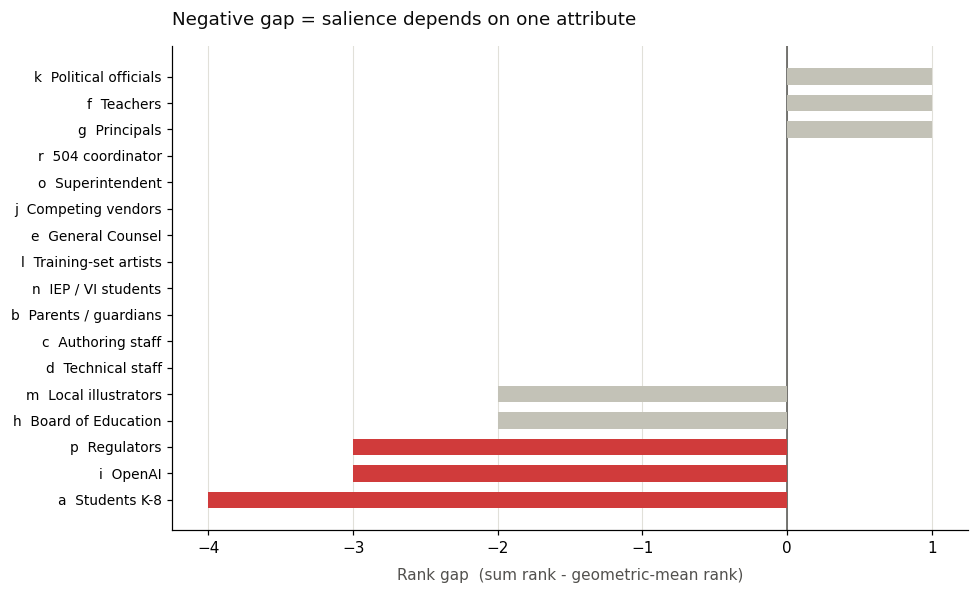

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))

d = ranked.sort_values("gap")
ypos = np.arange(len(d))
colors = ["#d03b3b" if g < -2 else "#c3c2b7" for g in d["gap"]]

ax.barh(ypos, d["gap"], color=colors, height=0.62, zorder=3)
ax.axvline(0, color="#52514e", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels(d["ref"] + "  " + d["stakeholder"], fontsize=9)
ax.set_xlabel("Rank gap  (sum rank - geometric-mean rank)",
              fontsize=10, color="#52514e", labelpad=8)
ax.set_title(
    "Negative gap = salience depends on one attribute",
    fontsize=12, color="#0b0b0b", pad=14, loc="left",
)
ax.grid(True, axis="x", color="#e1e0d9", lw=0.7, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "salience_rank_divergence.png",
            bbox_inches="tight", facecolor="white")
plt.show()

## 9. Optional — interactive version

Requires `plotly` (`pip install plotly`). Hover shows the full attribute
triple; useful in a working session, but the matplotlib figure in section 7 is
the one to drop into the deck.

In [11]:
# !pip install plotly

try:
    import plotly.express as px

    fig = px.scatter(
        df, x="power", y="legitimacy", size="urgency", color="salience_class",
        text="ref", hover_name="stakeholder",
        hover_data={"power": True, "legitimacy": True, "urgency": True,
                    "geom_mean": True, "ref": False, "salience_class": False},
        color_discrete_map=PALETTE,
        size_max=int(38 * SIZE_SCALE),
        range_x=[0.3, 5.8], range_y=[1.2, 5.9],
        labels={"power": "Power", "legitimacy": "Legitimacy",
                "salience_class": "Class"},
    )
    fig.update_traces(textposition="middle center",
                      textfont=dict(color="white", size=11))
    fig.add_vline(x=THRESHOLD, line_dash="dash", line_color="#c3c2b7")
    fig.add_hline(y=THRESHOLD, line_dash="dash", line_color="#c3c2b7")
    fig.update_layout(template="simple_white", height=620,
                      title="Stakeholder salience - bubble area = urgency")
    fig.show()
except ImportError:
    print("plotly not installed - run the pip line above to enable this cell.")

plotly not installed - run the pip line above to enable this cell.


## 10. Export

Writes the scored table back beside the source CSV, for Excel or Power BI if
the client prefers to rebuild the visual in their own toolchain. Both figures
were already saved to the same folder.

In [12]:
out = df[["ref", "stakeholder", "power", "legitimacy", "urgency",
          "salience_class", "power_derived", "sum", "geom_mean"]]

out_path = OUT_DIR / "salience_scores_plotted.csv"
out.to_csv(out_path, index=False)

print(str(len(out)) + " stakeholders written to " + str(out_path))
print("Excluded: " + (", ".join(sorted(EXCLUDE)) if EXCLUDE else "none"))
out

17 stakeholders written to /home/claude/salience_scores_plotted.csv
Excluded: q, s


,ref,stakeholder,power,legitimacy,urgency,salience_class,power_derived,sum,geom_mean
0,a,Students K-8,1,5,4,Dependent,False,10,2.71
1,b,Parents / guardians,2,5,3,Dependent,False,10,3.11
2,c,Authoring staff,2,4,5,Dependent,False,11,3.42
3,d,Technical staff,4,4,4,Definitive,False,12,4.00
4,e,General Counsel,4,5,4,Definitive,False,13,4.31
5,f,Teachers,2,4,3,Dependent,False,9,2.88
6,g,Principals,3,4,2,Dominant,False,9,2.88
7,h,Board of Education,5,5,2,Dominant,False,12,3.68
8,i,OpenAI,5,3,1,Dominant,False,9,2.47
9,j,Competing vendors,1,2,3,Demanding,False,6,1.82
